In [1]:
##Github link-https://github.com/2026845/Statistical-Techniques-


# Statistical Analysis of Online Retail Transactions

## Introduction

This project uses the Online Retail dataset from the UCI Machine Learning Repository. This is a UK-based online retailer and the data is from December 2010 to December 2011 with 541,909 transactions in total.

The dataset includes the following variables: Quantity, UnitPrice, InvoiceDate, InvoiceNo, StockCode, CustomerID and Country.

This analysis aims to describe the data using descriptive statistics and to describe the data using probability distributions. Bulk transaction lines are analyzed using the binomial distribution. Hourly transaction counts are analyzed using the Poisson distribution. UnitPrice as well as sample means are analyzed using the normal distribution.

In the first step of data preparation, records containing zero or negative values for Quantity and UnitPrice were removed from the dataset.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

In [3]:
df = pd.read_excel('Online Retail.xlsx')

In [4]:
df.shape

(541909, 8)

## Part 1: Descriptive Statistics

In [5]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


In [7]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [8]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

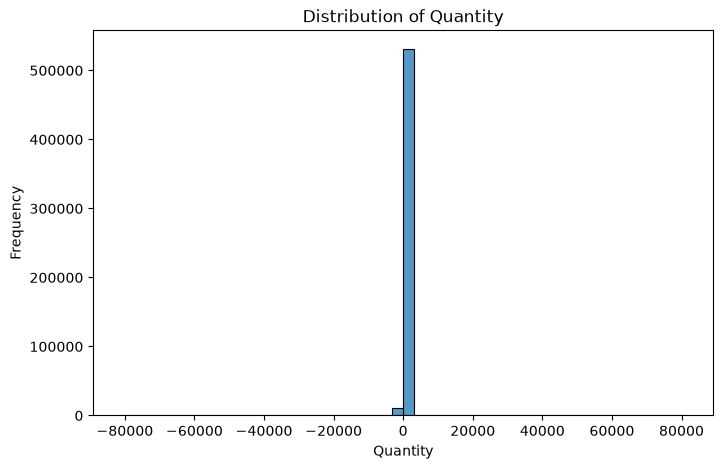

In [9]:
#Distribution of Quantity

plt.figure(figsize=(8, 5))

sns.histplot(df['Quantity'], bins=50)

plt.title('Distribution of Quantity')
plt.xlabel('Quantity')
plt.ylabel('Frequency')

plt.show()

### Interpretation of Quantity Distribution

This histogram shows the most of Quantity values are around zero with several very large positive and negative values. It is very hard to see the distribution of normal quantities because of those extreme values.
Therefore,more investigation of the data is needed.

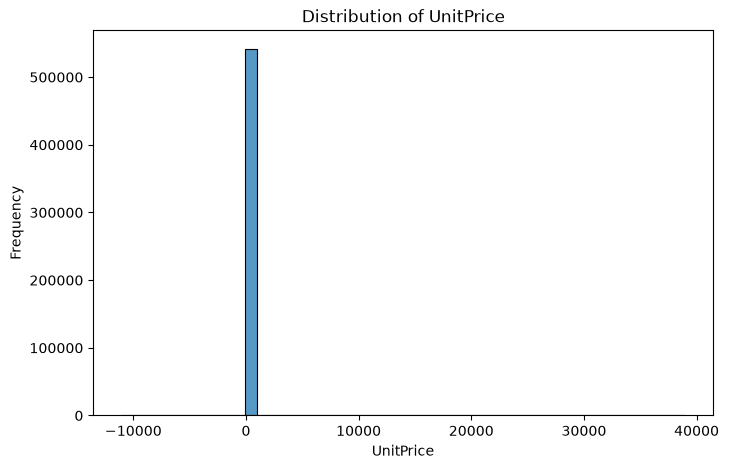

In [10]:
#Distribution of UnitPrice

plt.figure(figsize=(8, 5))

sns.histplot(df['UnitPrice'], bins=50)

plt.title('Distribution of UnitPrice')
plt.xlabel('UnitPrice')
plt.ylabel('Frequency')

plt.show()


### Interpretation of UnitPrice Distribution

The histogram shows that most UnitPrice values are shown in the lower price range. Although some extremely high and negative values are present making the distribution difficult to interpret clearly.More investigation of these extreme values is needed.


In [11]:
df = df[df['Quantity'] > 0]
df = df[df['UnitPrice'] > 0]

In [12]:
df.shape

(530104, 8)

In [13]:
df[['Quantity', 'UnitPrice']].describe()

,Quantity,UnitPrice
count,530104.000000,530104.000000
mean,10.542037,3.907625
std,155.524124,35.915681
min,1.000000,0.001000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,13541.330000



### Interpretation of Cleaned Data

After removing zero and negative values from Quantity and UnitPrice, 530104 observations are left.The minimum value for Quantity is 1 and the minimum value for UnitPrice is 0.001. However,there are some very high values for both variables.The mean value is higher than  median value for both variables and both variables are right skewed.

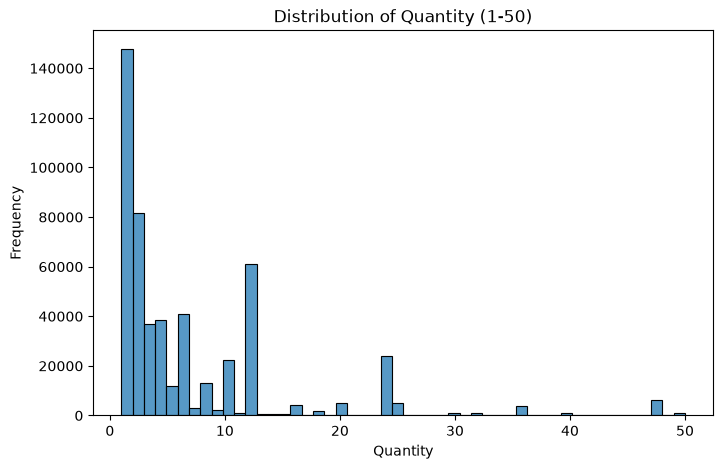

In [14]:
# Plot the distribution of Quantity between 1 and 50

plt.figure(figsize=(8, 5))

sns.histplot(df[df['Quantity'] <= 50]['Quantity'], bins=50)

plt.title('Distribution of Quantity (1-50)')
plt.xlabel('Quantity')
plt.ylabel('Frequency')

plt.show()


### Interpretation of Quantity Distribution (1–50)

The above histogram shows that most of the transactions are of small quantities. The frequency of larger quantities decreases with the increase in quantity.
Note that there are some peaks in the frequency for certain quantities like 12 and 24. The distribution of quantities is right-skewed as most of the quantities are of small size than the large size.


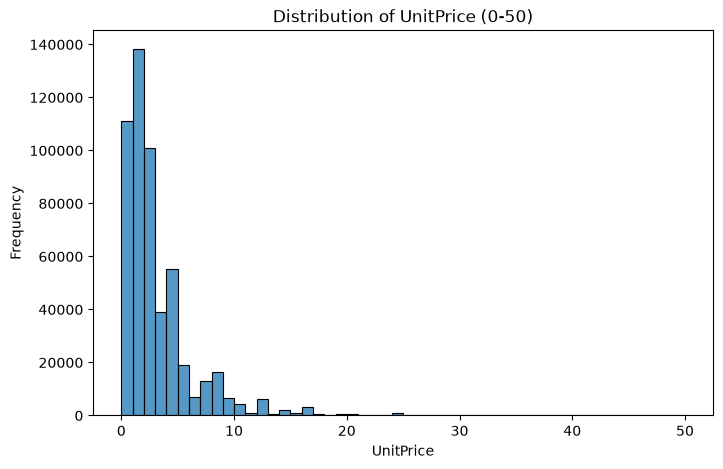

In [15]:
# Plot the distribution of UnitPrice between 0 and 50

plt.figure(figsize=(8, 5))

sns.histplot(df[df['UnitPrice'] <= 50]['UnitPrice'], bins=50)

plt.title('Distribution of UnitPrice (0-50)')
plt.xlabel('UnitPrice')
plt.ylabel('Frequency')

plt.show()



### Interpretation of UnitPrice Distribution (0–50)

We can see from this histogram that the majority of products are priced at a low unit price. Most of the products are shown on the graph with a price of between 1 and 3. The frequency of products with a high unit price is generally decreasing. This is a right skewed distribution with many products in the lower price range.


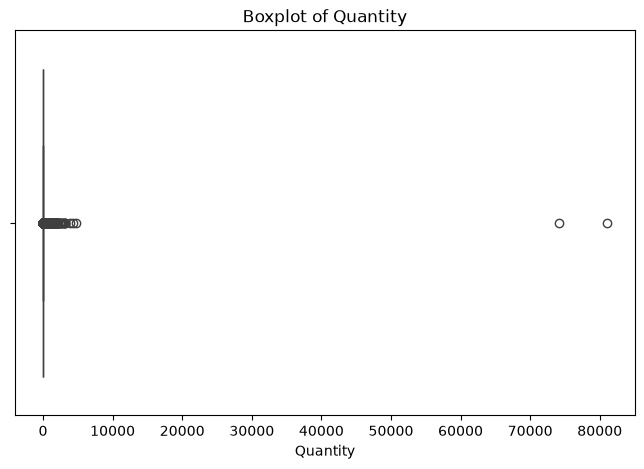

In [16]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df['Quantity'])

plt.title('Boxplot of Quantity')
plt.xlabel('Quantity')

plt.show()


### Interpretation of Quantity Boxplot

This boxplot shows that most of the data points for the variable Quantity fall within a very narrow range.However there are a few very extreme values. The median value for Quantity is 3 while the maximum value is 80995. This is a very right skewed distribution.It is possible that some of the very high values represent bulk purchases and should investigated before being deleted.


In [17]:

# Check Quantity outliers using IQR

Q1 = df['Quantity'].quantile(0.25)
Q3 = df['Quantity'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['Quantity'] < lower_bound) |
              (df['Quantity'] > upper_bound)]

print('Q1:', Q1)
print('Q3:', Q3)
print('IQR:', IQR)
print('Lower Bound:', lower_bound)
print('Upper Bound:', upper_bound)
print('Number of outliers:', len(outliers))


Q1: 1.0
Q3: 10.0
IQR: 9.0
Lower Bound: -12.5
Upper Bound: 23.5
Number of outliers: 56363



### Interpretation of Quantity Outliers####

There are 56,363 potential outliers in the data. They represent 10.63% of the cleaned data. The upper bound for these outliers is 23.5 and thus all quantities greater than 23 are potential outliers.
However,these outliers might be real bulk purchases thus are kept for analysis.


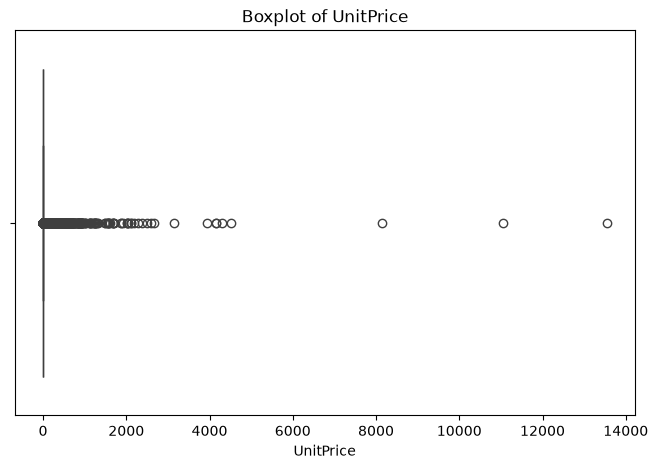

In [18]:
# Boxplot of UnitPrice

plt.figure(figsize=(8, 5))

sns.boxplot(x=df['UnitPrice'])

plt.title('Boxplot of UnitPrice')
plt.xlabel('UnitPrice')

plt.show()



### Interpretation of UnitPrice Boxplot

Unit prices have a large range of values but mostly low prices. The median price is 2.08 and maximum price is 13541.33. The data is highly positively skewed so we should look into the outliers.


In [19]:
# Check UnitPrice outliers using IQR

Q1 = df['UnitPrice'].quantile(0.25)
Q3 = df['UnitPrice'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['UnitPrice'] < lower_bound) |
              (df['UnitPrice'] > upper_bound)]

print('Q1:', Q1)
print('Q3:', Q3)
print('IQR:', IQR)
print('Lower Bound:', lower_bound)
print('Upper Bound:', upper_bound)
print('Number of outliers:', len(outliers))

Q1: 1.25
Q3: 4.13
IQR: 2.88
Lower Bound: -3.0700000000000003
Upper Bound: 8.45
Number of outliers: 37999



### Interpretation of UnitPrice Outliers

For the cleaned dataset with 534,136 observations and the IQR method identified 37,999 potential outliers which make up about 7.17% of the data. The upper bound for potential outliers is 8.45. Even though the unit prices of these potential outliers are above 8.45,they might represent higher priced products instead of errors so they are kept for further analysis.

In [20]:

# Calculate skewness and kurtosis for Quantity and UnitPrice

from scipy.stats import skew, kurtosis

quantity_skewness = skew(df['Quantity'])
unitprice_skewness = skew(df['UnitPrice'])

quantity_kurtosis = kurtosis(df['Quantity'])
unitprice_kurtosis = kurtosis(df['UnitPrice'])

print("Quantity Skewness:", quantity_skewness)
print("UnitPrice Skewness:", unitprice_skewness)

print("Quantity Kurtosis:", quantity_kurtosis)
print("UnitPrice Kurtosis:", unitprice_kurtosis)


Quantity Skewness: 471.72638151377913
UnitPrice Skewness: 206.08697179737123
Quantity Kurtosis: 236460.11248175093
UnitPrice Kurtosis: 62482.55335737786



### Interpretation of Skewness and Kurtosis

Both variables show a strong positive skewness with very high kurtosis values (471.73 and 206.09) and (236460.11 and 62482.55). Both variables therefore have heavy tails and a large influence from extreme values as can be seen from the histograms and boxplots.This shows that neither variable is normally distributed in their natural form.


In [21]:
# Calculate correlation between Quantity and UnitPrice

correlation = df['Quantity'].corr(df['UnitPrice'])

print("Correlation between Quantity and UnitPrice:", correlation)

Correlation between Quantity and UnitPrice: -0.0037725426616366884



### Interpretation of Correlation

The Pearson correlation coefficient between Quantity and UnitPrice is approximately -0.0038. This means that there is almost no linear relationship between the two variables,that is the quantity does not affect the unit price in any consistent way. Extreme values can affect the correlation coefficient.The Pearson correlation coefficient between Quantity and UnitPrice is approximately -0.0038. This means that there is almost no linear relationship between the two variables,that is the quantity does not affect the unit price in any consistent way. Extreme values can affect the correlation coefficient.


## Part 2: Discrete Probability Distributions

In [43]:

# Binomial Distribution - Bulk and Standard transactions

df['Bulk_Order'] = df['Quantity'] >= 10
print(df['Bulk_Order'].value_counts())
p = df['Bulk_Order'].mean()
print("Probability of Bulk Order:", p)


Bulk_Order
False    375591
True     154513
Name: count, dtype: int64
Probability of Bulk Order: 0.29147676682311396



### Binomial Distribution

For this analysis,we defined Bulk as any line with Quantity >= 10, and Standard as any line with Quantity < 10.
The number of Bulk records in the cleaned data is 154513 and the number of Standard records is 375591. The probability of selecting a Bulk record is 0.2915 or 29.15%.


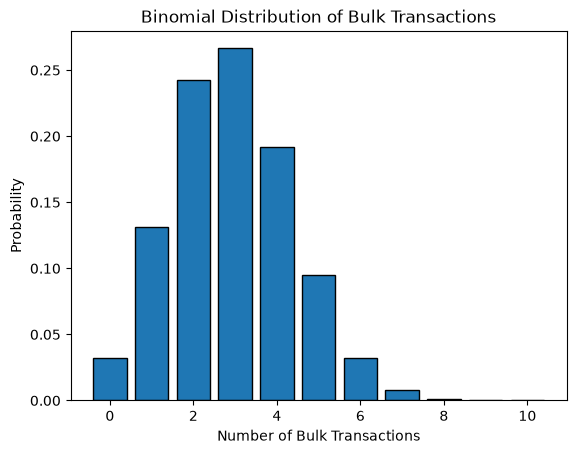

In [23]:
from scipy.stats import binom
import numpy as np
import matplotlib.pyplot as plt

n = 10
k = np.arange(0, n + 1)

binom_pmf = binom.pmf(k, n, p)

plt.bar(k, binom_pmf, edgecolor='black')
plt.title('Binomial Distribution of Bulk Transactions')
plt.xlabel('Number of Bulk Transactions')
plt.ylabel('Probability')
plt.show()


### Interpretation of Binomial Distribution

The following graph displays the binomial distribution of Bulk transaction lines within a sample of 10. There is approximately a 0.2915 probability that a transaction line will be a bulk record. The highest probability is for 3 bulk records (approximately 26.5%). As the number of bulk records increases,the probability decreases so using the binomial distribution, we would expect 3 Bulk transaction lines within a sample of 10.


In [24]:

# Probability of exactly 3 bulk transactions

n = 10
k = 3

probability = binom.pmf(k, n, p)

print("Probability of exactly 3 Bulk transactions:", probability)

Probability of exactly 3 Bulk transactions: 0.2663616809197078



### Binomial Probability Calculation

The probability of obtaining exact 3 Bulk transaction lines within a sample of 10 were calculated by using the binomial probability mass function with values of n = 10 and p = 0.2915. This gives us a probability of 0.2664 (26.64%). This shows that the most probable number of Bulk records within a sample of 10 assuming independent trials where the probability of success remains constant is 3.


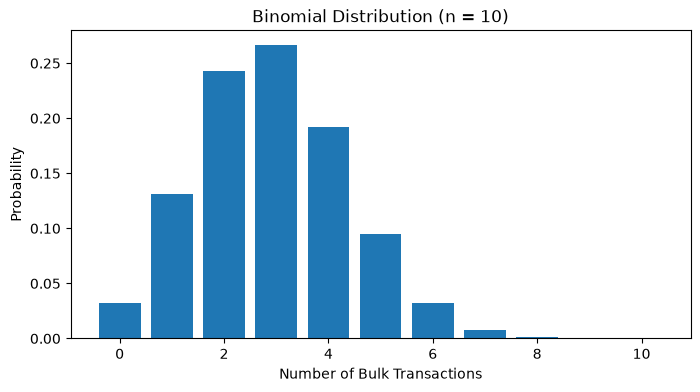

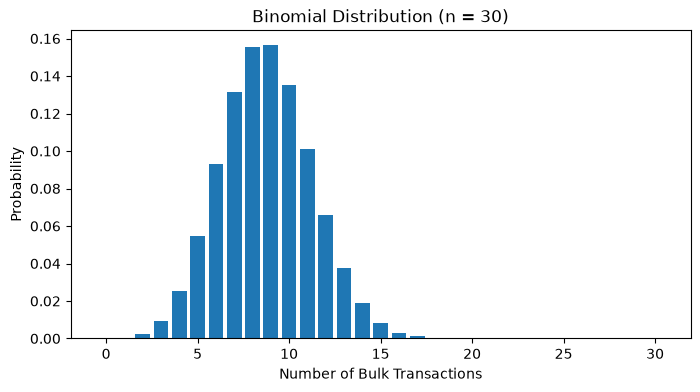

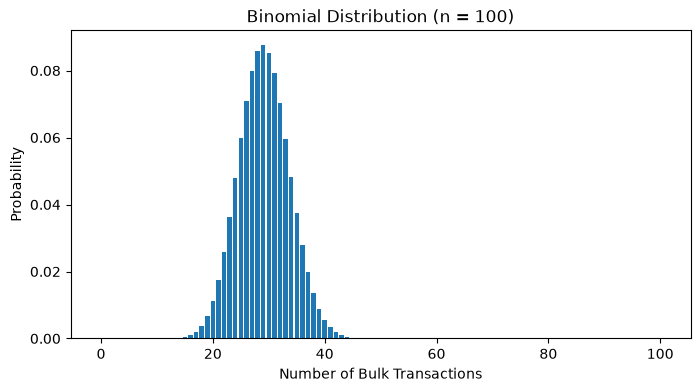

In [25]:

## Binomial distribution for different sample sizes

from scipy.stats import binom
import numpy as np
import matplotlib.pyplot as plt

for n in [10, 30, 100]:
    x = np.arange(0, n + 1)
    y = binom.pmf(x, n, p)
    plt.figure(figsize=(8, 4))
    plt.bar(x, y)
    plt.title('Binomial Distribution (n = ' + str(n) + ')')
    plt.xlabel('Number of Bulk Transactions')
    plt.ylabel('Probability')
    plt.show()



### Large Sample Behaviour of Binomial Distribution

The three graphs above plot the binomial distribution for a constant probability of a Bulk transaction of 0.2915 for sample sizes of 10,30 and 100.

For n=10 the distribution is slightly right skewed with highest probability for 3 Bulk records. For n=30 the distribution is symmetrical with highest probability for 9 Bulk records. For n=100 the distribution is almost bell-shaped with highest probability for 29 Bulk records.

This illustrates the binomial distribution approaching a normal distribution as the sample size is increased while the probability of success remains constant and the normal approximation is applicable.


In [26]:
##Count of transaction lines per day

df['Date'] = df['InvoiceDate'].dt.date
daily_counts = df.groupby('Date').size()
print(daily_counts.head())
print("Average transactions per day:", daily_counts.mean())


Date
2010-12-01    3072
2010-12-02    2063
2010-12-03    2155
2010-12-05    2708
2010-12-06    3816
dtype: int64
Average transactions per day: 1738.0459016393443


In [27]:
# Count transaction lines per hour

df['Hour'] = df['InvoiceDate'].dt.floor('h')
hourly_counts = df.groupby('Hour').size()
print(hourly_counts.head())
print("Average transactions per active hour:", hourly_counts.mean())
print("Number of active hours:", len(hourly_counts))


Hour
2010-12-01 08:00:00     46
2010-12-01 09:00:00    149
2010-12-01 10:00:00    114
2010-12-01 11:00:00    369
2010-12-01 12:00:00    420
dtype: int64
Average transactions per active hour: 182.7944827586207
Number of active hours: 2900


In [28]:
## Mean and variance of hourly transactions

hourly_mean = hourly_counts.mean()
hourly_variance = hourly_counts.var()
print("Mean:", hourly_mean)
print("Variance:", hourly_variance)
print("Variance / Mean:", hourly_variance / hourly_mean)


Mean: 182.7944827586207
Variance: 36306.80355699349
Variance / Mean: 198.62089385343464



### Interpretation of Poisson Mean and Variance

Average number of transaction lines per active hour is 182.79 with variance 36306.80. Variance-to-mean ratio is 198.62 or 198.62 times the mean.
The Poisson distribution has the mean equal to the variance, so the hourly counts do not fit this distribution well. The variation can be caused by the busy shopping hours and the fluctuations in the customers’ demand. Although Poisson distribution is a simple model,it fails to capture the variation in the data.


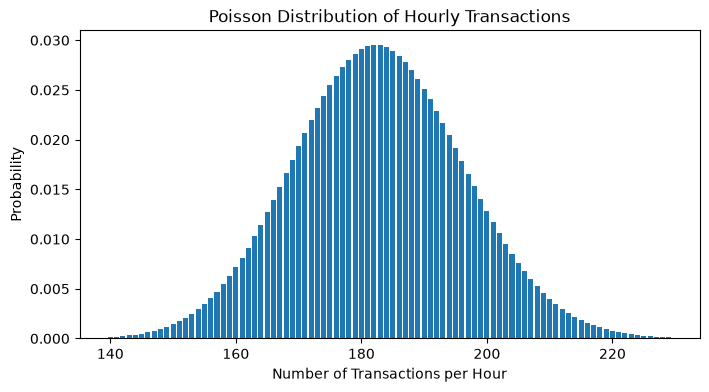

In [29]:
from scipy.stats import poisson
import numpy as np
import matplotlib.pyplot as plt

lam = hourly_counts.mean()

x = np.arange(140, 230)
y = poisson.pmf(x, lam)
plt.figure(figsize=(8, 4))
plt.bar(x, y)
plt.title('Poisson Distribution of Hourly Transactions')
plt.xlabel('Number of Transactions per Hour')
plt.ylabel('Probability')
plt.show()

### Interpretation of Poisson Distribution

The average of the transaction lines per active hour was used to model the Poisson distribution. The average of 182.79 transaction lines per active hour is used in the graph to center it around 183 transactions. The distribution is roughly bell-shaped because the mean is large enough.
However,the hourly data has more variance than the mean and so appears to be overdispersed.Therefore,the Poisson distribution may not accurately reflect the variation in hourly transaction numbers.


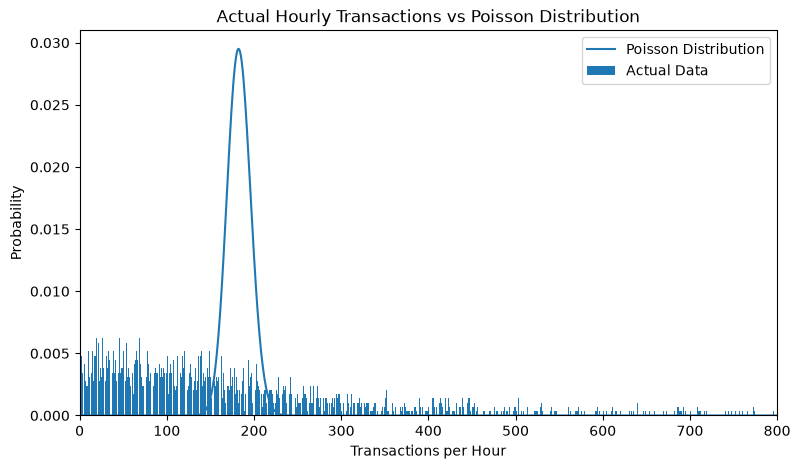

In [30]:

## Compare actual hourly counts with Poisson distribution


from scipy.stats import poisson
import numpy as np
import matplotlib.pyplot as plt

lam = hourly_counts.mean()

x = np.arange(0, 801)
y = poisson.pmf(x, lam)

actual = hourly_counts.value_counts(normalize=True)

plt.figure(figsize=(9, 5))

plt.bar(actual.index, actual.values, label='Actual Data')
plt.plot(x, y, label='Poisson Distribution')

plt.xlim(0, 800)
plt.xlabel('Transactions per Hour')
plt.ylabel('Probability')
plt.title('Actual Hourly Transactions vs Poisson Distribution')
plt.legend()
plt.show()



### Comparison of Actual Hourly Transactions and Poisson Distribution

The graph above shows that there are clear differences between the observed values and Poisson distribution. The Poisson distribution has a peak around the mean value with a value of 182.79 transactions per hour. However,the data is spread out much more.
The variance of the observed values is more higher than the mean value, with a variance of 36306.80. This means that we have overdisperison and the Poisson distribution does not provide a good fit for our data.


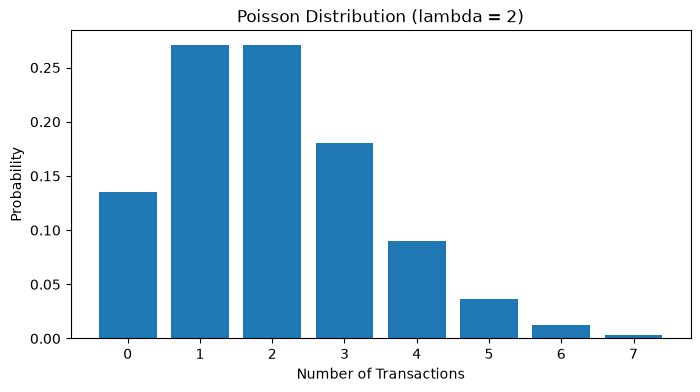

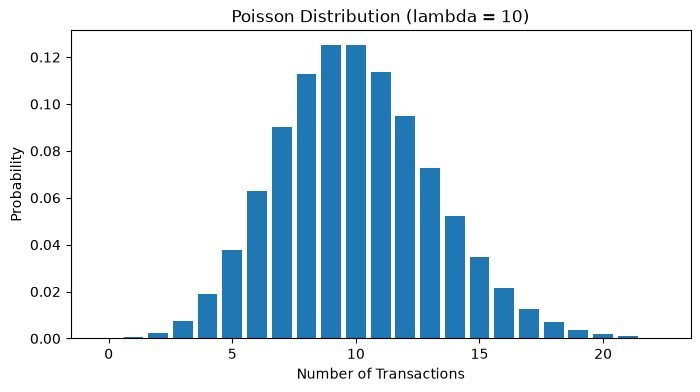

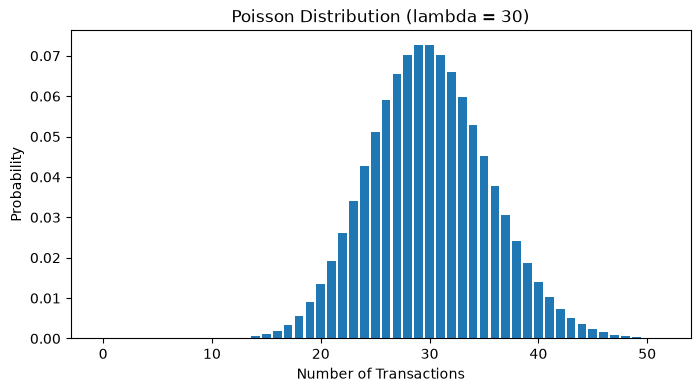

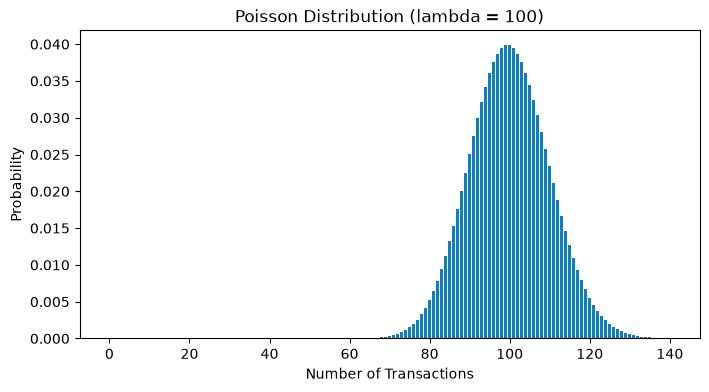

In [31]:

# Poisson distributions with different lambda values

from scipy.stats import poisson
import numpy as np
import matplotlib.pyplot as plt

for lam in [2, 10, 30, 100]:
    x = np.arange(0, int(lam + 4 * np.sqrt(lam)) + 1)
    y = poisson.pmf(x, lam)
    plt.figure(figsize=(8, 4))
    plt.bar(x, y)
    plt.title('Poisson Distribution (lambda = ' + str(lam) + ')')
    plt.xlabel('Number of Transactions')
    plt.ylabel('Probability')
    plt.show()



### Behaviour of Poisson Distribution with Increasing Lambda

The four plots on the right display the Poisson distribution as lambda is increased from 2 to 100.
The right-skewed distribution for lambda=2 has the majority of the probabilities for 1 and 2 events. For lambda=10 and lambda=30 the distribution becomes more symmetrical and for lambda=100 the distribution is approximately normal shaped.
In many cases the Poisson distribution can be approximated by a normal distribution when lambda is large enough. However,increasing lambda is not the same as increasing the sample size.


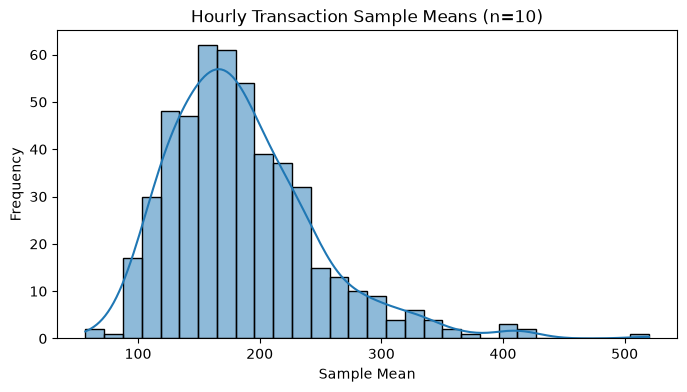

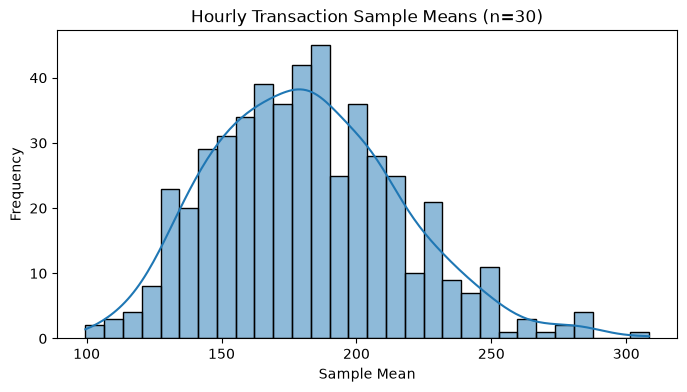

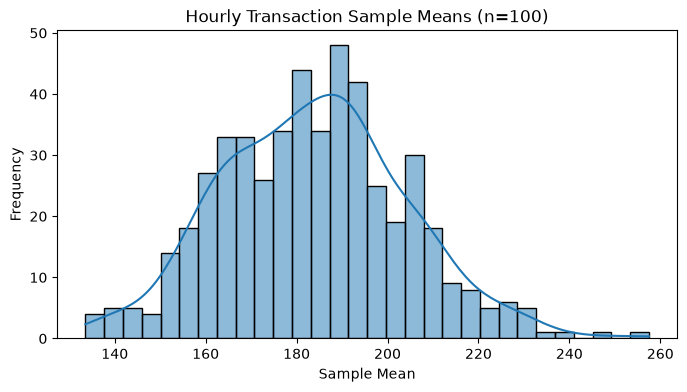

In [32]:

# Sample means of hourly transaction counts

for n in [10, 30, 100]:
    sample_means = []

    for i in range(500):
        sample = hourly_counts.sample(n=n, replace=True)
        sample_means.append(sample.mean())

    plt.figure(figsize=(8, 4))
    sns.histplot(sample_means, bins=30, kde=True)
    plt.title('Hourly Transaction Sample Means (n=' + str(n) + ')')
    plt.xlabel('Sample Mean')
    plt.ylabel('Frequency')
    plt.show()



### Large-Sample Behaviour of Hourly Transaction Counts

The plots below show the sample means for the hourly transaction counts for different sample sizes n=10,30,100. Each sample size was run 500 times.

For n=10 the distribution is right-skewed and the sample means are widely spread out.For n=30 and 100 the sample means are more concentrated about the mean of 182.79 and the distribution is more symmetric.

This result supports the Central Limit Theorem. However,the original hourly transaction counts are overdispersed and do not follow the Poisson distribution well.


## Part 3: Normal Distribution

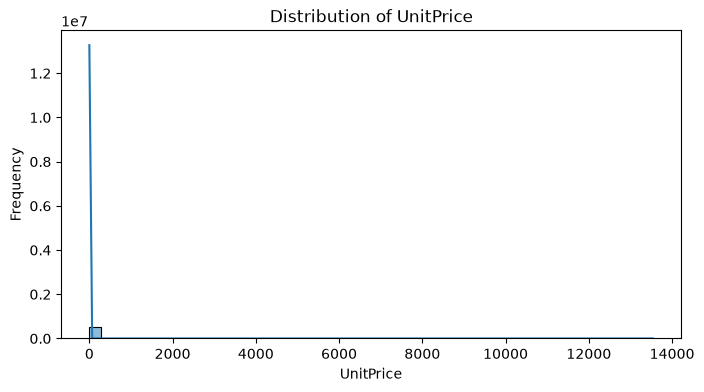

In [33]:

# Normal distribution - UnitPrice

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.histplot(df['UnitPrice'], bins=50, kde=True)
plt.title('Distribution of UnitPrice')
plt.xlabel('UnitPrice')
plt.ylabel('Frequency')
plt.show()



### Interpretation of UnitPrice Distribution

Most of the unit prices are concentrated in the lower part of the histogram. A few extreme values can seen in the right tail of the distribution. The distribution is highly right-skewed as oppose to symmetric. This is also indicated by the high skewness value of 206.09 for the original UnitPrice data.
So that the original UnitPrice data does not follow a normal distribution.

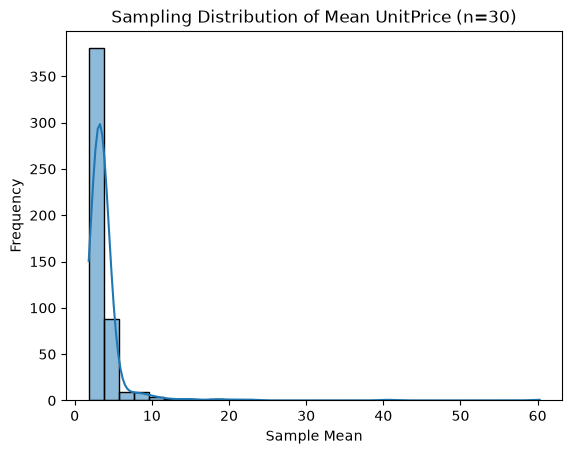

In [34]:

# Central Limit Theorem - UnitPrice sample means

np.random.seed(42)

sample_means = []

for i in range(500):
    sample = df['UnitPrice'].sample(n=30, replace=True)
    sample_means.append(sample.mean())

sns.histplot(sample_means, bins=30, kde=True)
plt.title('Sampling Distribution of Mean UnitPrice (n=30)')
plt.xlabel('Sample Mean')
plt.ylabel('Frequency')
plt.show()



### Interpretation of Central Limit Theorem (n = 30)

The sampling distribution of the mean UnitPrice was simulated using 500 samples of size 30. While most sample means are small,the sampling distribution is strongly right skewed.

The sampling distribution of the mean UnitPrice shown above is strongly right-skewed. The extreme values of the UnitPrice variable have clearly been preserved in the sampling distribution of the mean. Although the Central Limit Theorem states that as the sample size increases the sampling distribution of the mean approaches a normal distribution,a sample size of 30 is not large enough to produce an approximately normal distribution for this variable.


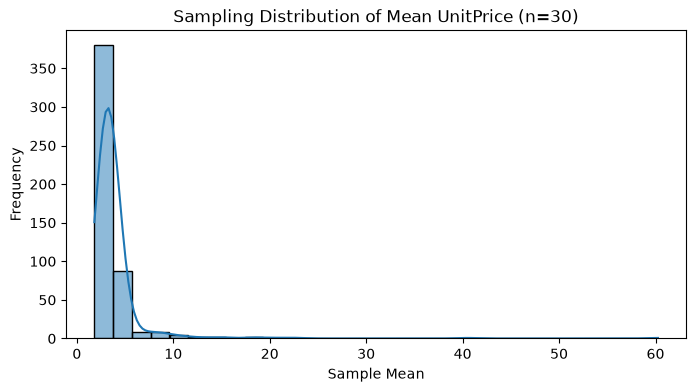

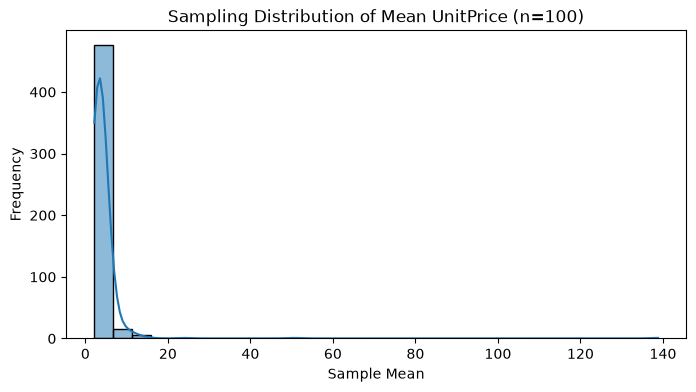

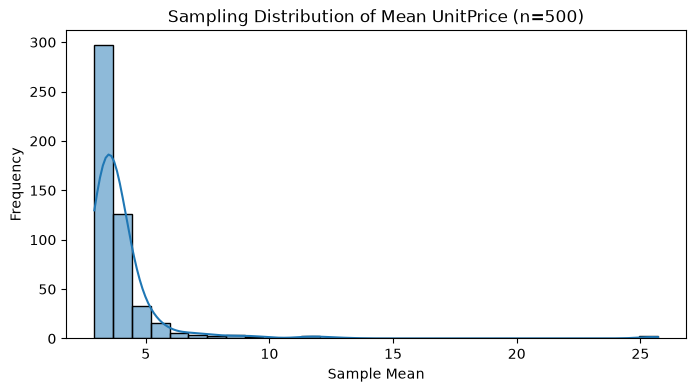

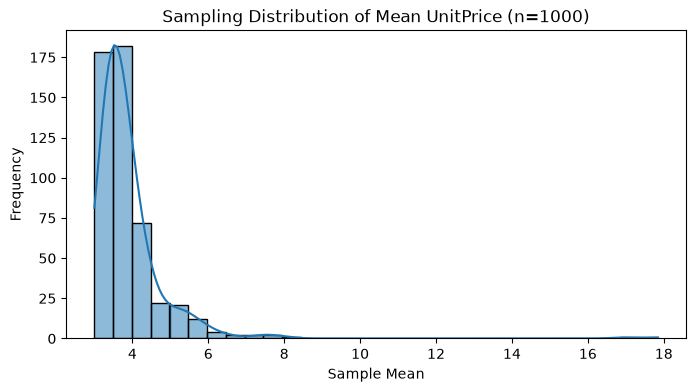

In [35]:

# CLT with different sample sizes

np.random.seed(42)

for n in [30, 100, 500, 1000]:
    sample_means = []

    for i in range(500):
        sample = df['UnitPrice'].sample(n=n, replace=True)
        sample_means.append(sample.mean())

    plt.figure(figsize=(8, 4))
    sns.histplot(sample_means, bins=30, kde=True)
    plt.title('Sampling Distribution of Mean UnitPrice (n=' + str(n) + ')')
    plt.xlabel('Sample Mean')
    plt.ylabel('Frequency')
    plt.show()



### Central Limit Theorem with Different Sample Sizes

For each of the sample sizes (30,100,500 and 1000) we created 500 repeated samples and used these to construct the sampling distributions.

For small samples,the sample means are strongly right-skewed. For larger samples,most of the sample means are concentrated but the sampling distributions have very long right tails and do not look like a normal distribution.

The extreme values of the original UnitPrice data may be affecting the results of the sampling distribution and it seems that a much larger sample size would be needed for sampling distribution become approximately normal.


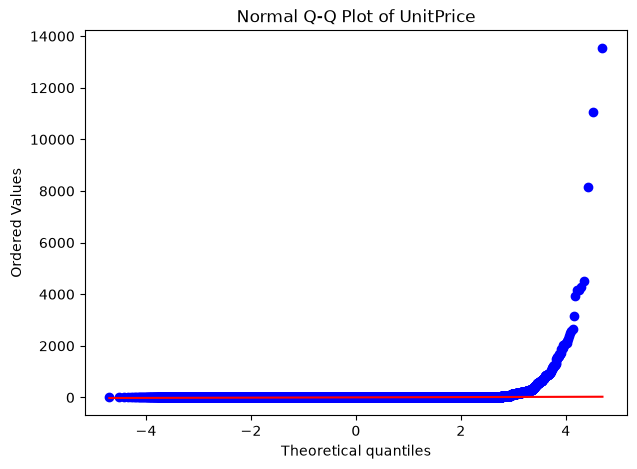

In [36]:

## Q-Q plot for UnitPrice

from scipy import stats
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
stats.probplot(df['UnitPrice'], dist='norm', plot=plt)
plt.title('Normal Q-Q Plot of UnitPrice')
plt.show()



### Interpretation of Normal Q-Q Plot

The Q-Q plot for UnitPrice deviates significantly from the straight line particularly for the upper part of the plot. The distribution is heavily right-skewed with extreme values on the high side.

This is also reflected in the histogram and the value for skewness of the original UnitPrice data which is not normally distributed.


In [40]:

# Mean and standard error of UnitPrice

import numpy as np

mean_price = df['UnitPrice'].mean()
std_price = df['UnitPrice'].std()
n = 1000
standard_error = std_price / np.sqrt(n)
print("Mean UnitPrice:", mean_price)
print("Standard Deviation:", std_price)
print("Standard Error:", standard_error)


Mean UnitPrice: 3.9076252471213193
Standard Deviation: 35.915681104255434
Standard Error: 1.1357535600571855



### Mean and Standard Error of UnitPrice

The mean of UnitPrice is 3.91 with a standard deviation of 35.92. For a sample size of 1000,the standard error of the mean is 1.14.

Note that the standard deviation is large for the mean of the UnitPrice variable. Even though the standard error decreases as the sample size increases,there are extreme values in the data set that can affect the normal approximation.


In [41]:
from scipy.stats import norm

probability = norm.cdf(5, loc=mean_price, scale=standard_error)
print("Probability that sample mean UnitPrice is below 5:", probability)


Probability that sample mean UnitPrice is below 5: 0.8319265045622737



### Interpretation of Normal Probability

The probability that the mean UnitPrice of 1000 randomly selected transaction lines is below 5 is approximately 0.8319 (83.19%) using the normal approximation.

Note that the sampling distribution remains right-skewed because of the extreme values in the original data so the probability is only an approximation of the sampling behavior.


In [42]:

# Estimate probability using repeated samples

np.random.seed(42)

sample_means = []

for i in range(500):
    sample = df['UnitPrice'].sample(n=1000, replace=True)
    sample_means.append(sample.mean())

sample_means = np.array(sample_means)
simulated_probability = np.mean(sample_means < 5)
print("Simulated probability:", simulated_probability)
print("Normal approximation:", probability)


Simulated probability: 0.902
Normal approximation: 0.8319265045622737



### Comparison of Normal Approximation and Simulation

Using the normal approximation we find that the probability of the mean UnitPrice of 1000 transaction lines being less than 5 is 83.19%. However,using simulation of 500 samples of 1000 transaction lines that we find the probability to be 90.20%.

The difference is 7.01%.So that normal approximation is not very good for this data set at this sample size. The extreme values and the right-skewness of UnitPrice are the reasons for this difference.

The simulation was run with a fixed random seed to ensure results are reproducible.


## Part 4: Distribution Justification and Limitations


### Why These Distributions Were Chosen

Since each transaction line was either classified Bulk or Standard,I used the binomial distribution for this analysis. I used Quantity 10 or more to classify as Bulk. The percentage of Bulk transaction lines in the cleaned data were 29.15%.

For the hourly count of transactions, I used the Poisson distribution. The average number of transaction lines per active hour was 182.79. However,the variance was much higher than the mean and so the model did not fit well.

The normal distribution was explored for UnitPrice and its sample means. UnitPrice is strongly right-skewed due to the some very high prices. Even with very large samples,the sampling distribution is not completely normal.



### Can Discrete Distributions Be Approximated by a Normal Distribution?

The binomial and Poisson distributions are discrete distributions deal with counts where the normal distribution is continuous distribution.

The binomial distribution can approximated by a normal distribution if both np and n(1-p) is greater than some value.In there p = 0.2915 and for n=100, we have np=29.15 and n(1-p)=70.85. The normal approximation would be reasonable if the binomial distribution was hold for this data.

For the Poisson distribution,the shape of distribution becomes more symmetric as the value of lambda increases. The graphs for lambda equal to 2,10,30 and 100 are shown on the right. Note however that the variance of the hourly transaction counts is much larger than the mean. So that normal approximation based on the Poisson model would not provide a good fit of data.

Therefore, discrete distributions can be approximated by a normal distribution in the exact cases but one have to consider the conditions as well as the actual data.